# 03 · Improve the model, and ship it as a new version

[Notebook 01](01-explain-a-model.ipynb) left two questions open:

- **Where is the forest wrong, and why?** Accuracy says 17% of the validation passengers are misclassified, not what those mistakes have in common.
- **Do its features say what they seem to?** Kaimei's analysis showed `Fare` interacting strongly with family size: a Kaggle fare is the price of a whole ticket, not of a seat.

This notebook answers both, builds a v2 of the forest with cleaner features, uploads it as **version 2** of the same model, and compares the two versions with Kaimei.

**Needs** notebook 01's models. **Uses** 1 more model (the new version), 18 explanations and 1 analysis of a free Kaimei plan.

**Before you start:** `pip install -r requirements.txt` from the repository root, and copy `.env.example` to `.env` with your Kaimei API key (dashboard → **API keys**). The notebook asks for the key if it can't find one.

> **Running on Google Colab or without a clone?** Install this example first; the data downloads by itself:
> ```python
> %pip install -q "titanic-kaimei-example[xgboost,serve] @ git+https://github.com/KaimeiAI/titanic-kaimei-example"
> ```

## 1. Connect

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kaimei import NotFoundError
from kaimei.tabular import SERIES, explanation_summary, plot_explanation, plot_insight
from titanic_kaimei import COLUMNS_V2, FEATURES_V2, encode, load, to_row, to_rows
from titanic_kaimei.models import make_forest, scores, split
from titanic_kaimei.workspace import FOREST, FOREST_V2, connect, dashboard_url, delete_if_exists, run_analysis

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

client = connect()
try:
    forest_model = client.models.retrieve(FOREST)
except NotFoundError:
    raise RuntimeError("Run notebook 01 first: it uploads the forest this notebook improves.") from None

Connected to Kaimei at https://api.kaimei.ai (workspace: Kaimei Workspace)


## 2. Where the forest goes wrong

The same forest as notebook 01 (same data, split and seed), scored on the 179 validation passengers it never saw:

In [2]:
v1 = load(1)
X1, y = encode(v1.passengers), v1.survived
X_train, X_valid, y_train, y_valid = split(X1, y)
forest = make_forest().fit(X_train, y_train)

predicted = pd.Series(forest.predict(X_valid), index=X_valid.index)
mistakes = v1.passengers.loc[X_valid.index][predicted != y_valid].assign(actually=y_valid[predicted != y_valid])
mistakes["group"] = mistakes["Sex"].map({"male": "men who survived", "female": "women who died"})
print(f"{len(mistakes)} of {len(y_valid)} validation passengers misclassified")
mistakes.groupby(["group", "Pclass"]).size().unstack(fill_value=0)

31 of 179 validation passengers misclassified


Pclass,1,2,3
group,,,
men who survived,8,2,10
women who died,1,0,10


Every mistake goes one way. The forest says men die and women survive, and the mistakes are the men who survived (mostly first and third class) and the women who died (mostly third class).

To see *why* it called them wrong, explain up to eight mistakes from each group with Kaimei and average the attributions per group. `log_prediction=False` keeps these diagnostic explanations out of the production traffic:

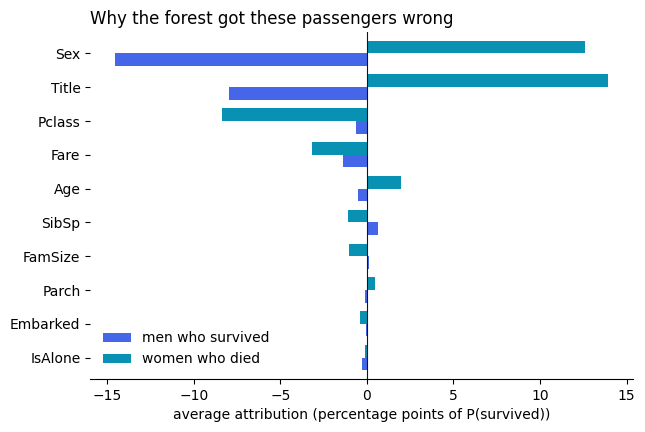

In [3]:
rows = []
for index, passenger in mistakes.groupby("group").head(8).iterrows():
    explanation = client.explanations.create(
        model=FOREST, input=to_row(passenger[v1.passengers.columns]), method="shap",
        options={"seed": 0, "log_prediction": False},
    )
    rows.append({"group": passenger["group"], **explanation.attributions})
attributions = pd.DataFrame(rows)

mean = attributions.groupby("group").mean().T * 100  # percentage points of P(survived)
mean = mean.loc[mean.abs().max(axis=1).sort_values().index]
ax = mean.plot.barh(figsize=(7, 4.5), color=[SERIES[0], SERIES[1]], width=0.75)
ax.axvline(0, color="#12141c", linewidth=0.8)
ax.set_xlabel("average attribution (percentage points of P(survived))")
ax.set_title("Why the forest got these passengers wrong", loc="left")
ax.legend(frameon=False)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.show()

For both groups the forest followed the strongest evidence it has: together, `Sex` and `Title` push the men down and the women up by more than 20 points. For the women, mostly third class, their class and cheap fares pull the other way, but by less than half as much. Nothing else in these features points the other way strongly enough. These passengers broke the pattern for reasons the passenger list doesn't record, such as where they were on the ship or which lifeboat they reached.

That's a useful conclusion in itself. Retraining or tuning won't fix these mistakes; only new information would. Explanations tell you which kind of problem you have before you spend a week on the wrong one.

## 3. Features that blur the model's reasons

Notebook 01's analysis is still on Kaimei:

In [4]:
v1_insights = {insight.type: insight for insight in client.insights.list(model=FOREST).data}
for pair in v1_insights["interactions"].payload["pairs"][:3]:
    print("interaction:", " × ".join(pair["features"]), f"{pair['strength']:.0%}")
shares = {row["feature"]: row["share"] for row in v1_insights["global_importance"].payload["features"]}
family = ["SibSp", "Parch", "FamSize", "IsAlone"]
print("importance of the four family features:", ", ".join(f"{name} {shares[name]:.0%}" for name in family))

interaction: Sex × Title 14%
interaction: Fare × FamSize 13%
interaction: Fare × Age 9%
importance of the four family features: SibSp 3%, Parch 2%, FamSize 4%, IsAlone 2%


Three things in v1's features make its explanations harder to trust than they should be:

- **A fare is per ticket.** Kaggle's `Fare` is the price of the whole ticket, shared by everyone travelling on it, so it mixes "expensive seat" with "big party". That's the strong `Fare × FamSize` interaction.
- **Family is counted four times.** `FamSize` and `IsAlone` are computed from `SibSp` and `Parch`, so the credit for family splits four ways. A what-if that changes one of them alone describes a passenger who can't exist, which is why notebook 01 had to freeze them in its counterfactuals.
- **Missing ages are invisible.** 177 passengers (20%) have no recorded age and were given the median, 28. The model can't tell them from real 28-year-olds, and nobody can tell whether that matters.

None of this shows up in the accuracy figure, and each makes the model's reasons harder to read.

## 4. Version 2 of the features

`load(2)` ([`src/titanic_kaimei/data.py`](../src/titanic_kaimei/data.py)) changes all three:

| v1 | v2 |
| --- | --- |
| `Fare` (whole ticket) | `FarePerPerson` = fare ÷ passengers on the ticket |
| `FamSize`, `IsAlone` (derived from `SibSp` and `Parch`) | `TicketSize`: passengers on the same ticket, the travelling party measured directly |
| missing age → 28 | missing age → the median age for the passenger's title (a `Master` is a boy), plus `AgeKnown` so the model can see it was missing |

In [5]:
v2 = load(2)
X2 = encode(v2.passengers)
pd.concat({"v1": v1.passengers.iloc[[0, 1, 5]], "v2": v2.passengers.iloc[[0, 1, 5]]}, axis=1)

v1                                                                      \
  Pclass     Sex   Age SibSp Parch   Fare     Embarked FamSize IsAlone Title   
0      3    male  22.0     1     0   7.25  Southampton       2   False    Mr   
1      1  female  38.0     1     0  71.28    Cherbourg       2   False   Mrs   
5      3    male  28.0     0     0   8.46   Queenstown       1    True    Mr   

      v2                                                              \
  Pclass     Sex   Age AgeKnown SibSp Parch FarePerPerson TicketSize   
0      3    male  22.0     True     1     0          7.25          1   
1      1  female  38.0     True     1     0         35.64          2   
5      3    male  30.0    False     0     0          8.46          1   

                      
      Embarked Title  
0  Southampton    Mr  
1    Cherbourg   Mrs  
5   Queenstown    Mr

In [6]:
forest_v2 = make_forest()
comparison = pd.concat({
    "v1": scores({"forest": make_forest()}, X1, y),
    "v2": scores({"forest": forest_v2}, X2, y),   # leaves forest_v2 fitted on the same 80% split
}).droplevel(1)
comparison

,5-fold CV accuracy,validation accuracy
v1,0.827,0.827
v2,0.828,0.816


Accuracy is about the same; the difference is within the noise of a 179-passenger validation set. v2 isn't a more accurate model. It's one whose reasons hold up, which is the point of this exercise.

## 5. Upload v2 as version 2

A **version** keeps the history of a model in one lineage: the dashboard's *Versions* tab lists them side by side, and each keeps its own traffic, explanations and insights. `create_version` copies v1 (schema, structure, reference data). Then:
- `update` swaps in the v2 feature schema ([`schema.py`](../src/titanic_kaimei/schema.py));
- `upload_structure` replaces the trees;
- `upload_reference_data` replaces the reference passengers.

In [7]:
delete_if_exists(client, FOREST_V2)  # running this notebook again replaces version 2
version = client.models.create_version(
    FOREST, version="2", slug=FOREST_V2, name="Titanic survival · random forest",
    description="v2: fare per person, age from title (+ AgeKnown), ticket size instead of family size.",
)
client.models.update(FOREST_V2, features=FEATURES_V2)
client.models.upload_structure(FOREST_V2, forest_v2, feature_names=COLUMNS_V2)
client.models.upload_reference_data(FOREST_V2, rows=to_rows(v2.passengers), labels=list(v2.survived))

pd.DataFrame([{"slug": v.slug, "version": v.version, "features": len(v.features)}
              for v in client.models.versions(FOREST).data])

,slug,version,features
0,titanic-forest,1,10
1,titanic-forest-v2,2,10


## 6. What changed in the model's reasons

In [8]:
v2_insights = run_analysis(client, FOREST_V2)
v2_model = client.models.retrieve(FOREST_V2)

for name, found in [("v1", v1_insights), ("v2", v2_insights)]:
    pairs = [f"{' × '.join(p['features'])} {p['strength']:.0%}" for p in found["interactions"].payload["pairs"][:4]]
    print(f"{name} strongest interactions: {', '.join(pairs)}")
for rule in v2_insights["learned_rules"].payload["rules"]:
    if rule["feature"] in ("FarePerPerson", "TicketSize"):
        print("v2 rule:", rule["statement"].replace("`", ""))
v2_shares = {row["feature"]: row["share"] for row in v2_insights["global_importance"].payload["features"]}
print(f"v2 importance: FarePerPerson {v2_shares['FarePerPerson']:.0%}, TicketSize {v2_shares['TicketSize']:.0%}, "
      f"AgeKnown {v2_shares['AgeKnown']:.1%}")

v1 strongest interactions: Sex × Title 14%, Fare × FamSize 13%, Fare × Age 9%, Title × Fare 4%
v2 strongest interactions: Title × TicketSize 16%, Sex × Title 10%, TicketSize × Age 9%, Title × FarePerPerson 8%
v2 rule: FarePerPerson has a non-monotonic effect on the probability of survived: it peaks around 26.55 GBP (range 30% → 52%).
v2 rule: TicketSize has a non-monotonic effect on the probability of survived: it peaks around 4 (range 37% → 42%).
v2 importance: FarePerPerson 19%, TicketSize 9%, AgeKnown 0.5%


- **Fare.** `Fare × FamSize` is gone, and its successor `FarePerPerson × TicketSize` isn't among the strongest pairs: a fare per person no longer depends on who else is on the ticket. `FarePerPerson` carries the fare signal by itself and is now the third most important input. The forest's answer is flat at about 31% up to £9 per person, climbs to about 52% by £27, and levels off above that.
- **Family.** `TicketSize` picks up what the four family features shared. Parties of two to four did best (up to 42%); passengers travelling alone and parties of seven or more did worst (37%). The strongest interaction left, `Title × TicketSize`, is a real one. In the training data every `Master` (a boy) on a ticket of four or fewer survived, while only 2 of the 19 on tickets of five or more did.
- **Missing ages.** `AgeKnown` carries well under 1% of the importance. Filling missing ages with a median wasn't distorting the forest much, and now that's measured rather than assumed.

The full v2 cards:

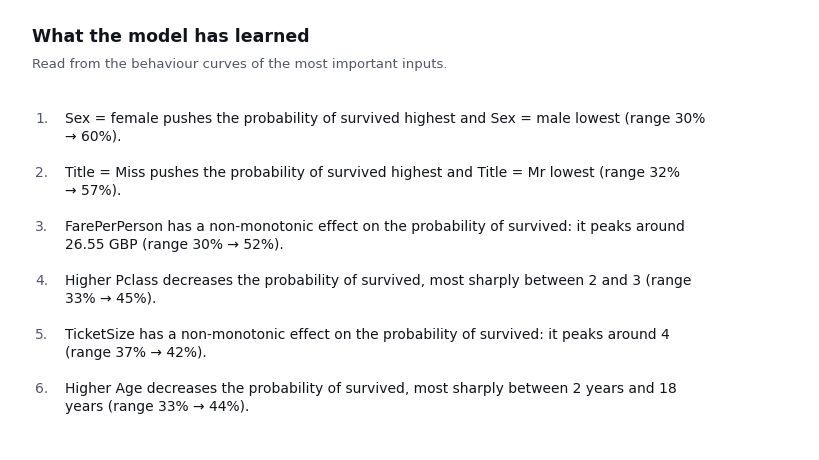

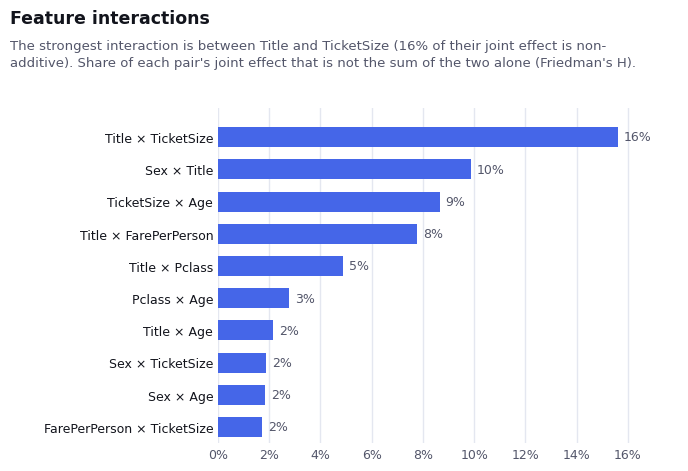

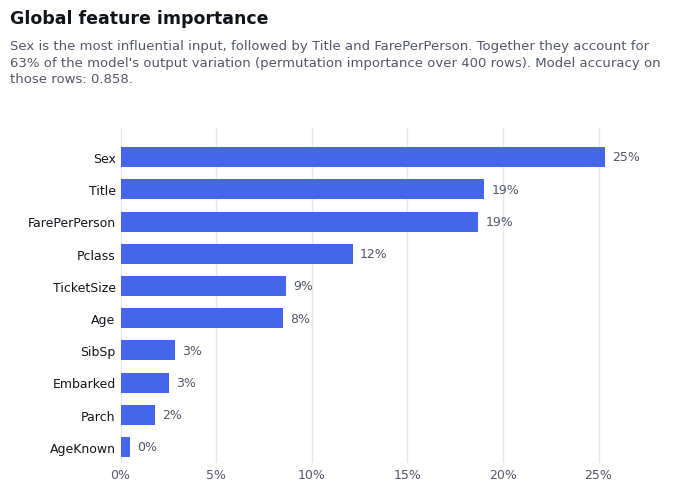

In [9]:
for kind in ["learned_rules", "interactions", "global_importance"]:
    plot_insight(v2_insights[kind], model=v2_model)
    plt.show()

## 7. The same passengers under v2

The model predicts died: P(survived) = 7.1%, against 40.0% on average over the reference data. Pulling P(survived) down: Sex = male (−13.6 pts), Title = Mr (−7.6 pts), FarePerPerson = 7.25 GBP (−5.2 pts).


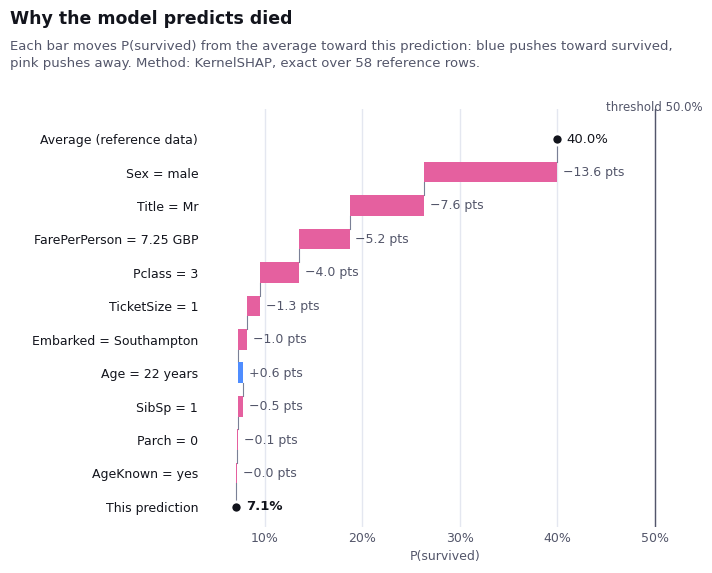

The model predicts survived: P(survived) = 96.2%, against 40.0% on average over the reference data. Pushing P(survived) up: Sex = female (+19.7 pts), FarePerPerson = 35.64 GBP (+11.6 pts), Pclass = 1 (+10.9 pts).


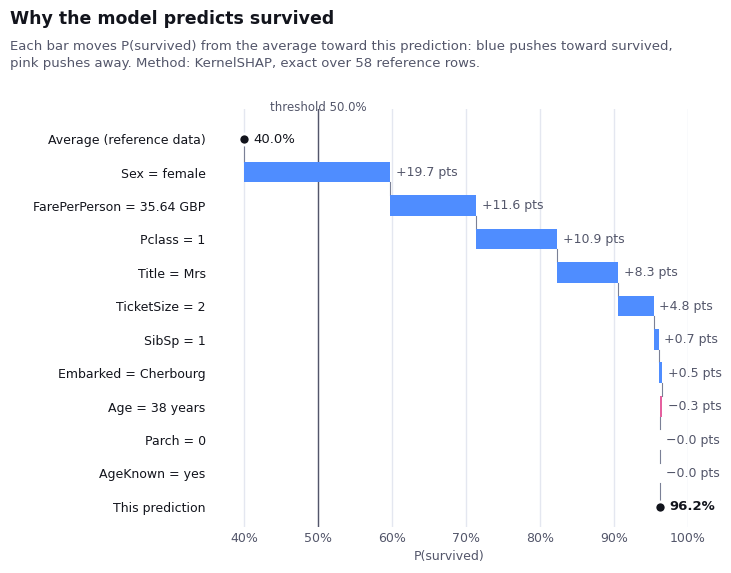

In [10]:
for index in (0, 1):
    passenger = to_row(v2.passengers.iloc[index])
    explanation = client.explanations.create(model=FOREST_V2, input=passenger, method="shap",
                                             options={"seed": 0, "log_prediction": False})
    print(explanation_summary(explanation, model=v2_model))
    plot_explanation(explanation, model=v2_model)
    plt.show()

Mr Braund's and Mrs Cumings's predictions barely move. Mrs Cumings's fare now reads as about £36 per person rather than £71 for the ticket she shared with her husband.

## 8. Shipping it

Kaimei records the versions; deciding which one serves traffic is up to your deployment. Typical next steps:

- run v2 in shadow next to v1, as [notebook 02](02-monitor-in-production.ipynb) did with the logistic regression, and compare their predictions on live traffic;
- when you switch, log traffic to the new version's slug, so drift and behaviour are tracked per version;
- retire the old version with `client.models.update(FOREST, status="archived")`. It stays in the lineage, with its history.

**Next:** [04 · Bring your own model](04-bring-your-own-model.ipynb) explains a model Kaimei can't run itself.

In [11]:
print(dashboard_url(f"models/{FOREST_V2}"))
print(dashboard_url(f"models/{FOREST}/versions"))

https://dashboard.kaimei.ai/models/titanic-forest-v2
https://dashboard.kaimei.ai/models/titanic-forest/versions
